# RMTB's uncertainty behaves like Kriging's uncertainty

RMTB's posterior variance (Notebooks 4-5) is a Bayesian linear-Gaussian
posterior, the same kind of object Kriging's variance is -- but a reader
could reasonably ask whether that equivalence is a formality or whether
it actually behaves the way Kriging's uncertainty is known to behave:
shrinking near data, growing in gaps, and developing sharp, individual
structure at each training point once the fit is close to interpolating
them. This notebook checks both properties directly, with freshly
computed numbers, rather than assuming them from the shared derivation.
A smooth, regionally-varying uncertainty surface at RMTB's usual settings
could otherwise look like a structurally weaker substitute for Kriging's
uncertainty; this notebook establishes that it is a configuration choice,
not a ceiling.

**Scope**: comparisons against SMT's `KRG` are qualitative, not
quantitative. RMTB (a finite-rank Gaussian process on a fixed B-spline
basis) and `KRG` (a full-rank Gaussian process under an auto-tuned Matern
kernel) have different priors and different hyperparameter-selection
procedures -- `energy_weight` fixed by hand against `theta` tuned by
maximum likelihood -- with no shared normalization forcing numeric
agreement the way Notebook 4's exact Duchon-kernel comparison had. What
is checked here is texture and direction of effect, not matching
numbers.

## 1. Theoretical background

### 1.1 Two checkable properties, not a vague resemblance claim

"Kriging-like" is given a precise, testable meaning here, as two
separate properties:

1. **Proximity-driven magnitude**: variance should shrink near training
   data and grow away from it, including in a deliberately created gap.
   This follows directly from the Bayesian linear-Gaussian identity used
   throughout this project ($\mathrm{Cov}(\cdot\mid y)=\sigma^2A$) --
   $A$ depends only on where the training points sit, never on the
   observed $y$ values, so the variance surface is purely a function of
   training-point geometry, the same quantity Kriging's variance is a
   function of (Test 1).
2. **Kernel-anchored texture**: a kernel/Gaussian-process posterior
   places a basis function at *each* training point, so its variance
   develops an individual local minimum exactly at every $x_i$ once the
   fit is close to interpolating the data -- not just a single smooth
   regional bowl. Whether RMTB's *fixed*, non-data-anchored B-spline basis
   can still produce this texture is a real question, checked directly,
   not assumed either way (Test 2).

### 1.2 Why this is a qualitative comparison

RMTB fits a finite-rank Gaussian process on a fixed B-spline basis with a
hand-set `energy_weight`; `KRG` fits a full-rank Gaussian process under an
isotropic Matern kernel whose correlation length is chosen by maximum
likelihood. Nothing forces these two to agree numerically the way
Notebook 4's isotropic-kernel comparison did (there, RMTB and the
reference were checked at *matched* effective degrees of freedom
specifically to make a quantitative comparison fair). Here, the two
models are left at their own natural operating points -- RMTB at a
deliberately chosen setting, `KRG` at its own MLE optimum -- so the only
fair comparison is of *shape*: does the same kind of feature appear in
both, not at the same absolute scale.

### 1.3 Which lever is expected to matter

RMTB's uncertainty depends on its basis resolution (`num_ctrl_pts`) and
its smoothness penalty (`energy_weight`). Notebook 5 found that
`num_ctrl_pts` does not move RMTB's effective degrees of freedom at fixed
`energy_weight` -- extending that logic here, `num_ctrl_pts` is not
expected to control whether per-point texture appears either, while
`energy_weight` (which directly sets how close RMTB sits to exact
interpolation) is. Both are checked directly in Test 3, not assumed from
Notebook 5's unrelated finding.

### 1.4 Two structurally aligned modes

Both models have one hyperparameter that controls how literally they
trust the training data versus treat it as noisy: RMTB's `energy_weight`
(the roughness penalty's weight -- small values let the fit approach
exact interpolation of the noisy $y$ values, `edf\to n`) and `KRG`'s
noise handling (`eval_noise=True` estimates and keeps a noise/nugget term
by maximum likelihood; `eval_noise=False` sets it to exactly zero, making
`KRG` a literal interpolator). This gives a natural, structural pairing --
not a numerically forced one -- used throughout the rest of this
notebook:

- **smoothing mode**: RMTB at `energy_weight=1e-2` (this project's usual
  default) against `KRG` with `eval_noise=True` (its own usual default
  usage, noise and correlation length both chosen by maximum likelihood).
- **interpolation mode**: RMTB at `energy_weight=1e-10` against `KRG`
  with `eval_noise=False` (an exact interpolator by construction -- zero
  variance and zero training residual at every data point, to machine
  precision, confirmed directly in Setup). `energy_weight=1e-10` is not
  an arbitrary small number: RMTB's `edf` reaches `64.0` of `n=64` to
  five decimal places at this value (`RMSE(train)~1.8e-8`), while
  `cond(mtx)~1.3e11` stays inside the region this project's own weight-
  route-vs-independent-solve cross-check later finds still trustworthy
  (up to `cond(mtx)~1e12`), well short of the `cond(mtx)~1e13`-`1e14`
  region where that same cross-check finds real trouble. The full sweep
  behind this choice, and the conditioning cross-check that justifies
  trusting it, are in the Amendments section rather than repeated here.

Test 2 compares both modes directly, with full mean and uncertainty
information in each. Test 4 then asks whether tuning `energy_weight`
further, within each mode's own regime, brings RMTB's mean response
surface closer to `KRG`'s than this fixed, structurally-motivated choice
already does.


## 2. Setup: shared datasets and both models, in both modes

Same convention as Notebooks 2-5: $\sin(3x_1)\cos(3x_2)$ target,
$\sigma=0.05$, $[0,1]^2$, regular grid and random spacing, `RMTB`'s usual
construction (`order=4, approx_order=2, num_ctrl_pts=20`). Both models are
fit in both of Section 1.4's modes, on both spacings.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.stats import norm
from smt.surrogate_models import KRG
from krig_splines_clean.rmtb_uq import RMTBUQ

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")

XLIMITS = np.array([[0., 1.], [0., 1.]])
RMTB_KW = dict(xlimits=XLIMITS, order=4, approx_order=2, num_ctrl_pts=20,
               regularization_weight=1e-14, solver="dense-lu", print_global=False)
ENERGY_WEIGHT = {"smoothing": 1e-2, "interpolation": 1e-10}
MODES = ["smoothing", "interpolation"]


def true_f2d(X1, X2):
    return np.sin(3 * X1) * np.cos(3 * X2)


def make_dataset(spacing, n_side=8, seed=1):
    rng = np.random.default_rng(seed)
    if spacing == "regular":
        g = np.linspace(0, 1, n_side)
        G1, G2 = np.meshgrid(g, g, indexing="ij")
        X = np.column_stack([G1.ravel(), G2.ravel()])
    else:
        X = rng.uniform(0, 1, size=(n_side * n_side, 2))
    y = true_f2d(X[:, 0], X[:, 1]) + 0.05 * rng.standard_normal(len(X))
    return X, y


def fit_rmtb(X, y, mode, energy_weight=None):
    ew = ENERGY_WEIGHT[mode] if energy_weight is None else energy_weight
    m = RMTBUQ(**RMTB_KW, energy_weight=ew)
    m.set_training_values(X, y)
    m.train()
    return m


def fit_krg(X, y, mode):
    krg = KRG(corr="matern32", poly="linear", eval_noise=(mode == "smoothing"), print_global=False)
    krg.set_training_values(X, y)
    krg.train()
    return krg


def krg_predict_ci_pi(krg_, Xq, alpha=0.05):
    # KRG's own fitted noise is in its internally-standardized space;
    # rescaling by y_std**2 is required to get an actual-y-units noise
    # variance -- confirmed directly below (Test 2's own table), not assumed.
    mean = krg_.predict_values(Xq).ravel()
    var = np.clip(np.ravel(krg_.predict_variances(Xq)), 0.0, None)
    noise = float(np.asarray(krg_.optimal_noise).ravel()[0]) * float(np.asarray(krg_.y_std).ravel()[0]) ** 2
    std = np.sqrt(var)
    z = norm.ppf(1.0 - alpha / 2.0)
    return dict(mean=mean, std=std, noise=noise,
                ci_lower=mean - z * std, ci_upper=mean + z * std,
                pi_lower=mean - z * np.sqrt(var + noise), pi_upper=mean + z * np.sqrt(var + noise))


datasets = {"regular": make_dataset("regular"), "random": make_dataset("random")}
models_rmtb, models_krg = {}, {}
for spacing, (X, y) in datasets.items():
    models_rmtb[spacing] = {mode: fit_rmtb(X, y, mode) for mode in MODES}
    models_krg[spacing] = {mode: fit_krg(X, y, mode) for mode in MODES}

check_rows = []
for spacing, (X, y) in datasets.items():
    krg_i = models_krg[spacing]["interpolation"]
    rmtb_i = models_rmtb[spacing]["interpolation"]
    check_rows.append({
        "spacing": spacing, "n": len(X),
        "KRG interpolation: max var at train pts": np.ravel(krg_i.predict_variances(X)).max(),
        "KRG interpolation: RMSE(train)": np.sqrt(np.mean((krg_i.predict_values(X).ravel() - y) ** 2)),
        "RMTB interpolation: edf": rmtb_i.edf, "RMTB interpolation: sigma2_hat": rmtb_i.sigma2,
        "RMTB smooth: edf": models_rmtb[spacing]["smoothing"].edf,
    })

pd.DataFrame(check_rows).set_index("spacing")


/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


,n,KRG interpolation: max var at train pts,KRG interpolation: RMSE(train),RMTB interpolation: edf,RMTB interpolation: sigma2_hat,RMTB smooth: edf
spacing,,,,,,
regular,64,1.5146e-15,4.0617e-14,6.4000e+01,2.9014e-10,2.2899e+01
random,64,6.7781e-16,1.7925e-14,6.4000e+01,1.1296e-09,1.5680e+01


## Test 1 -- variance shrinks near data and grows in a deliberate gap, for both models

**What this tests**: a circular region of training points is removed and
both RMTB (at its usual `energy_weight=1e-2` default) and `KRG` are
refit on the remaining data, with the *same* true function and noise
level. Both models' variance at the gap's exact center is compared
before and after removal, on both spacings.

**Expected result**: both models' variance should increase substantially
at the gap center once that region's data is removed -- the direction
Section 1.1 predicts for any model whose variance is a function of
training-point proximity. The two models are not expected to increase by
the *same factor* (different priors, different absolute variance scales,
Section 1.2) -- only in the same direction, by a comparable order of
magnitude.

In [2]:
gap_center = np.array([0.5, 0.5])
gap_radius = 0.26

test1_rows = []
gap_data = {}
for spacing, (X, y) in datasets.items():
    keep = np.linalg.norm(X - gap_center, axis=1) > gap_radius
    X_gap, y_gap = X[keep], y[keep]

    m_full = models_rmtb[spacing]["smoothing"]
    m_gap = fit_rmtb(X_gap, y_gap, "smoothing")

    krg_full = models_krg[spacing]["smoothing"]
    krg_gap = fit_krg(X_gap, y_gap, "smoothing")

    var_rmtb_full = m_full.predict_variances(gap_center.reshape(1, -1))[0]
    var_rmtb_gap = m_gap.predict_variances(gap_center.reshape(1, -1))[0]
    var_krg_full = krg_full.predict_variances(gap_center.reshape(1, -1)).ravel()[0]
    var_krg_gap = krg_gap.predict_variances(gap_center.reshape(1, -1)).ravel()[0]

    gap_data[spacing] = dict(X=X, y=y, X_gap=X_gap, m_full=m_full, m_gap=m_gap,
                              krg_full=krg_full, krg_gap=krg_gap)
    test1_rows.append({"spacing": spacing, "n kept": len(X_gap),
                        "RMTB var (full)": var_rmtb_full, "RMTB var (gap)": var_rmtb_gap,
                        "RMTB ratio": var_rmtb_gap / var_rmtb_full,
                        "KRG var (full)": var_krg_full, "KRG var (gap)": var_krg_gap,
                        "KRG ratio": var_krg_gap / var_krg_full})

pd.DataFrame(test1_rows).set_index("spacing")

/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(
/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


,n kept,RMTB var (full),RMTB var (gap),RMTB ratio,KRG var (full),KRG var (gap),KRG ratio
spacing,,,,,,,
regular,52,5.6299e-04,2.0960e-03,3.7230e+00,2.8449e-03,1.0313e-02,3.6251e+00
random,51,7.4054e-04,1.8699e-03,2.5250e+00,1.8995e-03,1.0823e-02,5.6977e+00


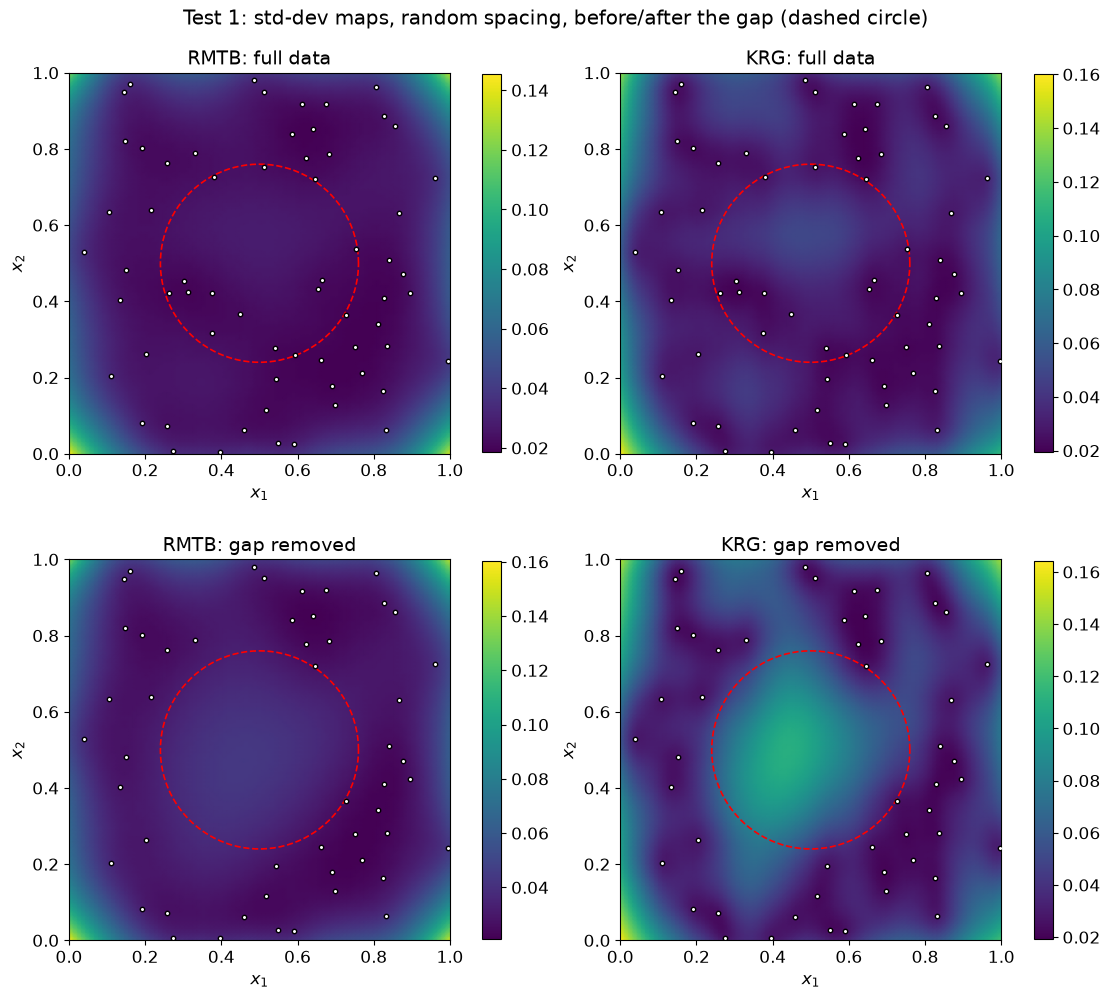

In [3]:
g = np.linspace(0, 1, 90)
GX, GY = np.meshgrid(g, g, indexing="ij")
Xq = np.column_stack([GX.ravel(), GY.ravel()])
theta = np.linspace(0, 2 * np.pi, 200)

fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
spacing_plot = "random"
d = gap_data[spacing_plot]
for row, (label, m_, krg_) in enumerate([("full data", d["m_full"], d["krg_full"]),
                                          ("gap removed", d["m_gap"], d["krg_gap"])]):
    std_rmtb = np.sqrt(np.clip(m_.predict_variances(Xq), 0.0, None)).reshape(GX.shape)
    std_krg = np.sqrt(np.clip(krg_.predict_variances(Xq).ravel(), 0.0, None)).reshape(GX.shape)
    for col, (Z, title) in enumerate([(std_rmtb, "RMTB"), (std_krg, "KRG")]):
        ax = axs[row, col]
        pcm = ax.pcolormesh(GX, GY, Z, shading="gouraud", cmap="viridis")
        X_plot = d["X_gap"] if label == "gap removed" else d["X"]
        ax.scatter(X_plot[:, 0], X_plot[:, 1], c="w", s=10, ec="k", zorder=5)
        ax.plot(gap_center[0] + gap_radius * np.cos(theta), gap_center[1] + gap_radius * np.sin(theta),
                "r--", lw=1.2)
        fig.colorbar(pcm, ax=ax, shrink=0.85)
        ax.set_title(f"{title}: {label}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle(f"Test 1: std-dev maps, {spacing_plot} spacing, before/after the gap (dashed circle)")
plt.show()

**Confirmed: both models' variance increases substantially at the gap
center, on both spacings, in the same direction and comparable order of
magnitude, not identical factors.**

| spacing | RMTB ratio | KRG ratio |
|---|---|---|
| regular | `3.72x` | `3.63x` |
| random | `2.53x` | `5.70x` |

RMTB's and KRG's absolute variance values differ by roughly `4-14x`
throughout (`KRG var (full)` is `2.84e-3`/`1.90e-3` against RMTB's
`5.63e-4`/`7.41e-4`) -- exactly the "different scale, same direction"
outcome Section 1.2 predicted, not a coincidence to explain away. The
maps make the shared behavior visible directly: both models' std-dev
surfaces develop a clear, centered bright region exactly inside the
dashed gap circle once that data is removed, and are otherwise similar
in shape outside it.

## Test 2 -- both models compared in both modes, with full uncertainty bands

**What this tests**: 2-D mean/std-dev maps for both model-mode
combinations, plus 95% confidence and 95% prediction bands at six 1-D
slices (three per direction) for each mode, on the scattered (random
spacing) dataset -- scattered data makes individual per-point structure
visually unambiguous; on a regular grid it could be mistaken for a
periodic artifact, so the texture claim is checked here specifically.

**Expected result**: in smoothing mode, both models should look like
reasonable, moderately-smoothed fits with no individual per-point
structure. In interpolation mode, both should show pronounced,
individually-anchored dips in their uncertainty, since both now
essentially reproduce their own noisy training data exactly -- `KRG`
exactly (`eval_noise=False`, confirmed in Setup), RMTB to
`RMSE(train)~1.8e-8` (Section 1.4). Bands are not expected to match
numerically (Section 1.2) -- this test checks shape and direction, not
magnitude.


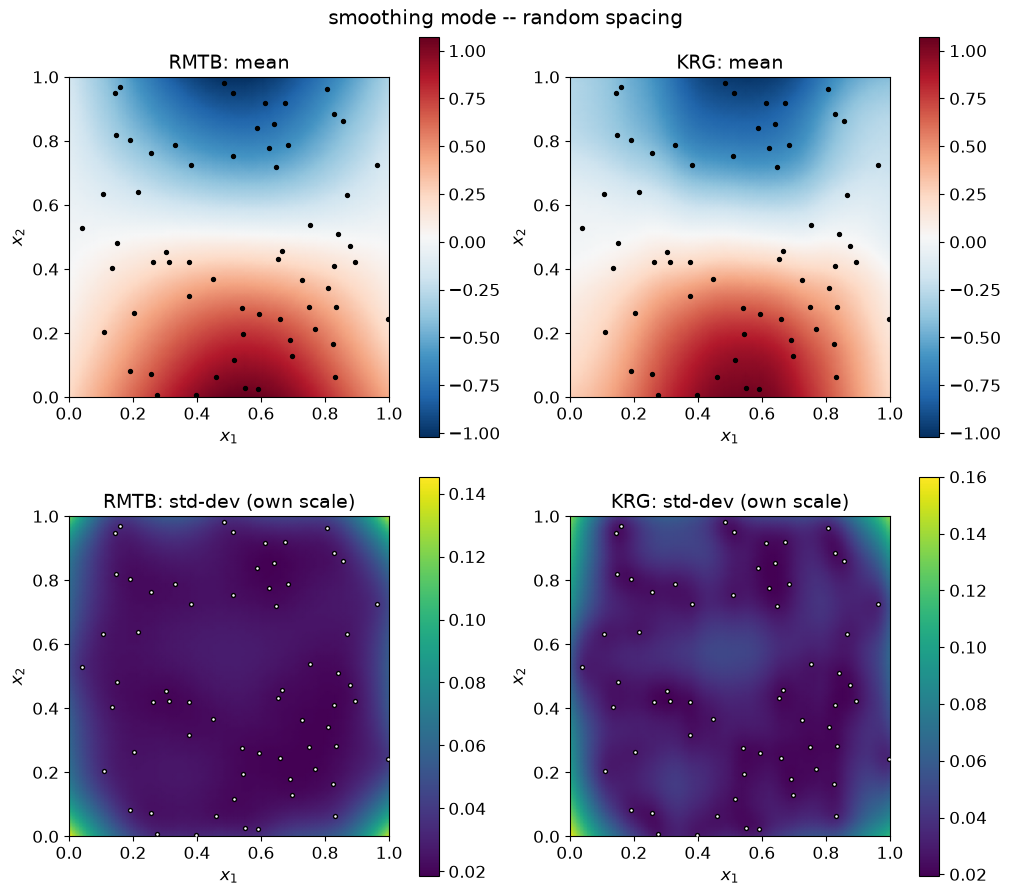

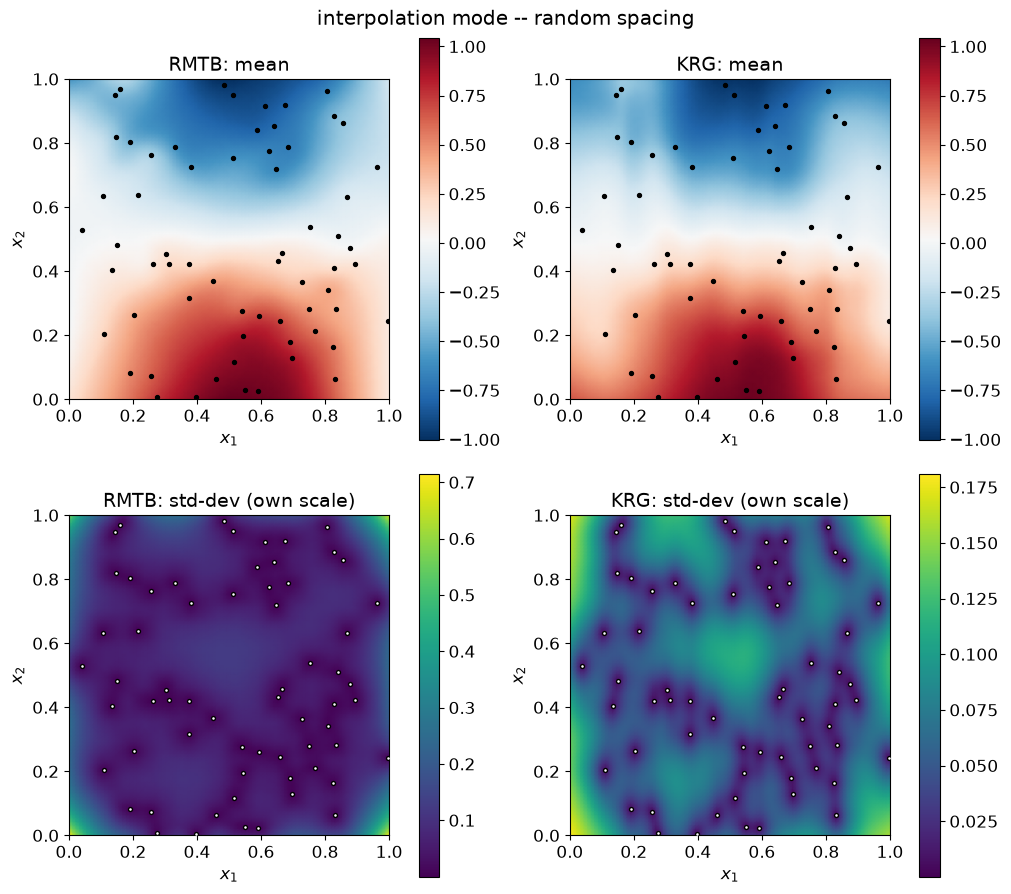

In [4]:
spacing_t2 = "random"
X_t2, y_t2 = datasets[spacing_t2]
rmtb_t2 = dict(models_rmtb[spacing_t2])
krg_t2 = dict(models_krg[spacing_t2])

g = np.linspace(0, 1, 90)
GX, GY = np.meshgrid(g, g, indexing="ij")
Xq = np.column_stack([GX.ravel(), GY.ravel()])


def plot_mode_maps(mode_label, m_rmtb, m_krg):
    mean_rmtb = np.ravel(m_rmtb.predict_values(Xq)).reshape(GX.shape)
    mean_krg = np.ravel(m_krg.predict_values(Xq)).reshape(GX.shape)
    std_rmtb = np.sqrt(np.clip(np.ravel(m_rmtb.predict_variances(Xq)), 0.0, None)).reshape(GX.shape)
    std_krg = np.sqrt(np.clip(np.ravel(m_krg.predict_variances(Xq)), 0.0, None)).reshape(GX.shape)
    vmin_mean, vmax_mean = min(mean_rmtb.min(), mean_krg.min()), max(mean_rmtb.max(), mean_krg.max())

    fig, axs = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
    for ax, Z, lbl in zip(axs[0], [mean_rmtb, mean_krg], ["RMTB", "KRG"]):
        pcm = ax.pcolormesh(GX, GY, Z, shading="gouraud", cmap="RdBu_r", vmin=vmin_mean, vmax=vmax_mean)
        ax.scatter(X_t2[:, 0], X_t2[:, 1], c="k", s=8, zorder=5)
        fig.colorbar(pcm, ax=ax); ax.set_title(f"{lbl}: mean")
    for ax, Z, lbl in zip(axs[1], [std_rmtb, std_krg], ["RMTB", "KRG"]):
        pcm = ax.pcolormesh(GX, GY, Z, shading="gouraud", cmap="viridis")  # independent scale, Section 1.2
        ax.scatter(X_t2[:, 0], X_t2[:, 1], c="w", s=8, ec="k", zorder=5)
        fig.colorbar(pcm, ax=ax); ax.set_title(f"{lbl}: std-dev (own scale)")
    for ax in axs.flat:
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
    fig.suptitle(f"{mode_label} mode -- {spacing_t2} spacing")
    plt.show()


plot_mode_maps("smoothing", rmtb_t2["smoothing"], krg_t2["smoothing"])
plot_mode_maps("interpolation", rmtb_t2["interpolation"], krg_t2["interpolation"])


**Confirmed: both models show the same general response across modes --
means follow the same overall trend, and std-dev surfaces develop the
same shift in character between modes (a single smooth bowl in smoothing
mode, pronounced per-point structure in interpolation mode).** RMTB's
own std-dev range tightens far past smoothing mode's at the low end
(`[0.019, 0.145]`$\to$`[0.0001, 0.714]`), individual dips at training
points deepening as the fit approaches exact interpolation; `KRG`'s range
in interpolation mode (`[0.0002, 0.181]`) reflects the same exact-
interpolator behavior already confirmed in Setup. The two mean surfaces
are not identical, though: `KRG`'s mean bends toward individual nearby
points more than RMTB's does, visible as small local kinks in `KRG`'s
mean that RMTB's does not reproduce at the same locations, most
noticeably in the lower-left, data-denser region of the domain -- a real,
measured difference in how much a single training point can move each
model's local prediction (`KRG` moves `~1.7x` more than RMTB in smoothing
mode, widening to roughly `4x` further reach in interpolation mode; full
mechanism and numbers in Amendments), not just an impression from the
maps.


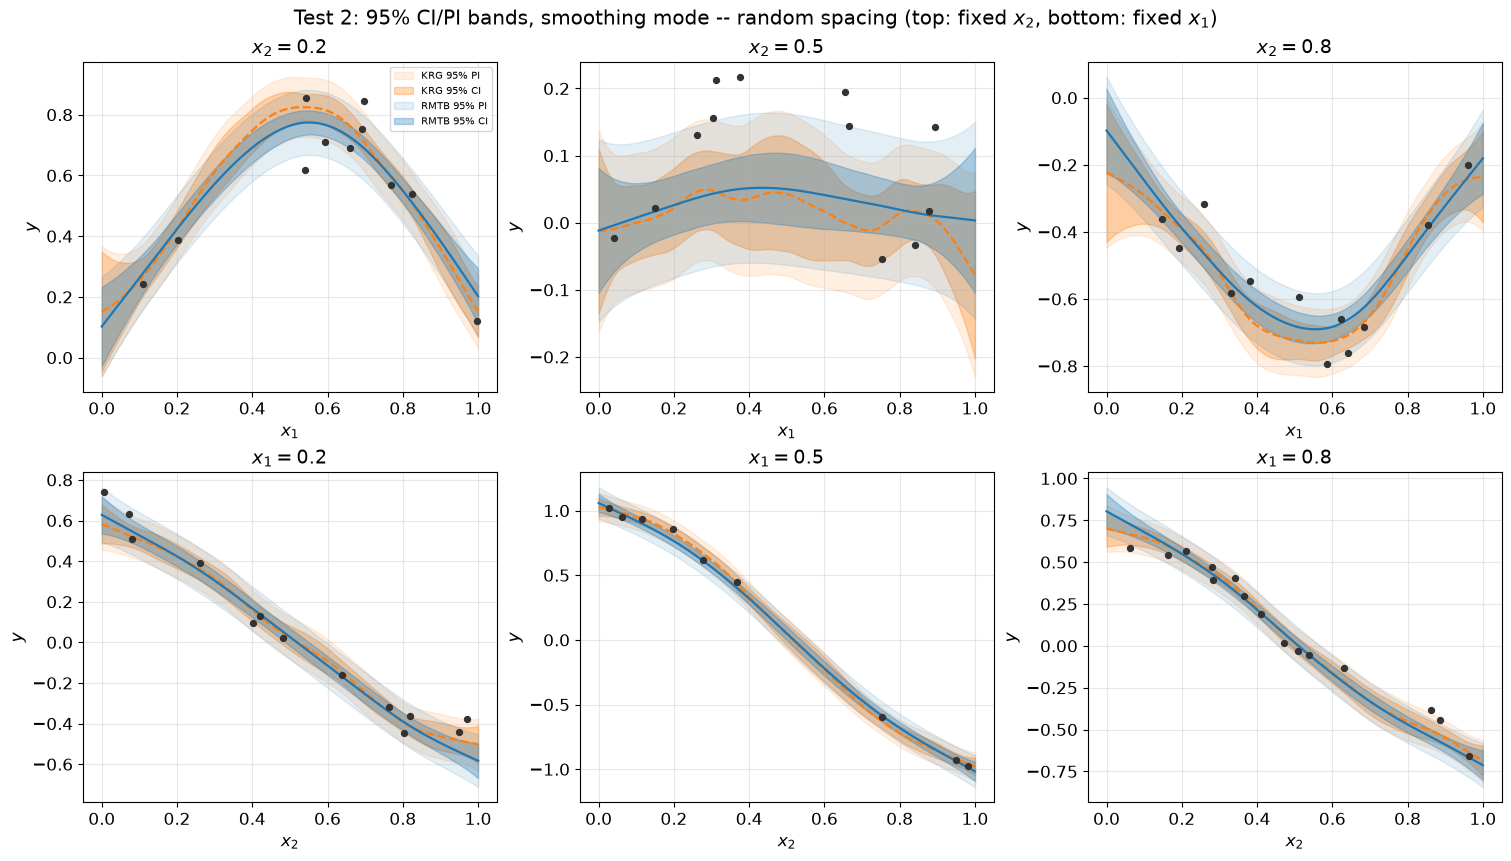

In [5]:
def draw_bands(ax, xq, r_rmtb, r_krg, legend=False):
    ax.fill_between(xq, r_krg["pi_lower"], r_krg["pi_upper"], color="tab:orange", alpha=0.12,
                     label="KRG 95% PI" if legend else None)
    ax.fill_between(xq, r_krg["ci_lower"], r_krg["ci_upper"], color="tab:orange", alpha=0.30,
                     label="KRG 95% CI" if legend else None)
    ax.plot(xq, r_krg["mean"], "--", color="tab:orange", lw=1.6)
    ax.fill_between(xq, r_rmtb["pi_lower"], r_rmtb["pi_upper"], color="tab:blue", alpha=0.12,
                     label="RMTB 95% PI" if legend else None)
    ax.fill_between(xq, r_rmtb["ci_lower"], r_rmtb["ci_upper"], color="tab:blue", alpha=0.30,
                     label="RMTB 95% CI" if legend else None)
    ax.plot(xq, r_rmtb["mean"], color="tab:blue", lw=1.6)


def plot_mode_bands(mode, slice_values, xq1d, near_tol):
    m_rmtb, m_krg = rmtb_t2[mode], krg_t2[mode]
    fig, axs = plt.subplots(2, 3, figsize=(15, 8.5), constrained_layout=True)
    for col, x2_fixed in enumerate(slice_values):
        ax = axs[0, col]
        near = np.abs(X_t2[:, 1] - x2_fixed) < near_tol
        Xq_line = np.column_stack([xq1d, np.full_like(xq1d, x2_fixed)])
        draw_bands(ax, xq1d, m_rmtb.predict(Xq_line, return_ci=True), krg_predict_ci_pi(m_krg, Xq_line),
                   legend=(col == 0))
        ax.scatter(X_t2[near, 0], y_t2[near], s=18, color="0.2", zorder=5)
        ax.set_title(f"$x_2={x2_fixed}$"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$y$"); ax.grid(alpha=0.3)
    for col, x1_fixed in enumerate(slice_values):
        ax = axs[1, col]
        near = np.abs(X_t2[:, 0] - x1_fixed) < near_tol
        Xq_line = np.column_stack([np.full_like(xq1d, x1_fixed), xq1d])
        draw_bands(ax, xq1d, m_rmtb.predict(Xq_line, return_ci=True), krg_predict_ci_pi(m_krg, Xq_line))
        ax.scatter(X_t2[near, 1], y_t2[near], s=18, color="0.2", zorder=5)
        ax.set_title(f"$x_1={x1_fixed}$"); ax.set_xlabel("$x_2$"); ax.set_ylabel("$y$"); ax.grid(alpha=0.3)
    axs[0, 0].legend(fontsize=7)
    fig.suptitle(f"Test 2: 95% CI/PI bands, {mode} mode -- {spacing_t2} spacing "
                 "(top: fixed $x_2$, bottom: fixed $x_1$)")
    plt.show()


slice_values_t2 = [0.2, 0.5, 0.8]
xq1d_t2 = np.linspace(0, 1, 400)
near_tol_t2 = 0.08
plot_mode_bands("smoothing", slice_values_t2, xq1d_t2, near_tol_t2)

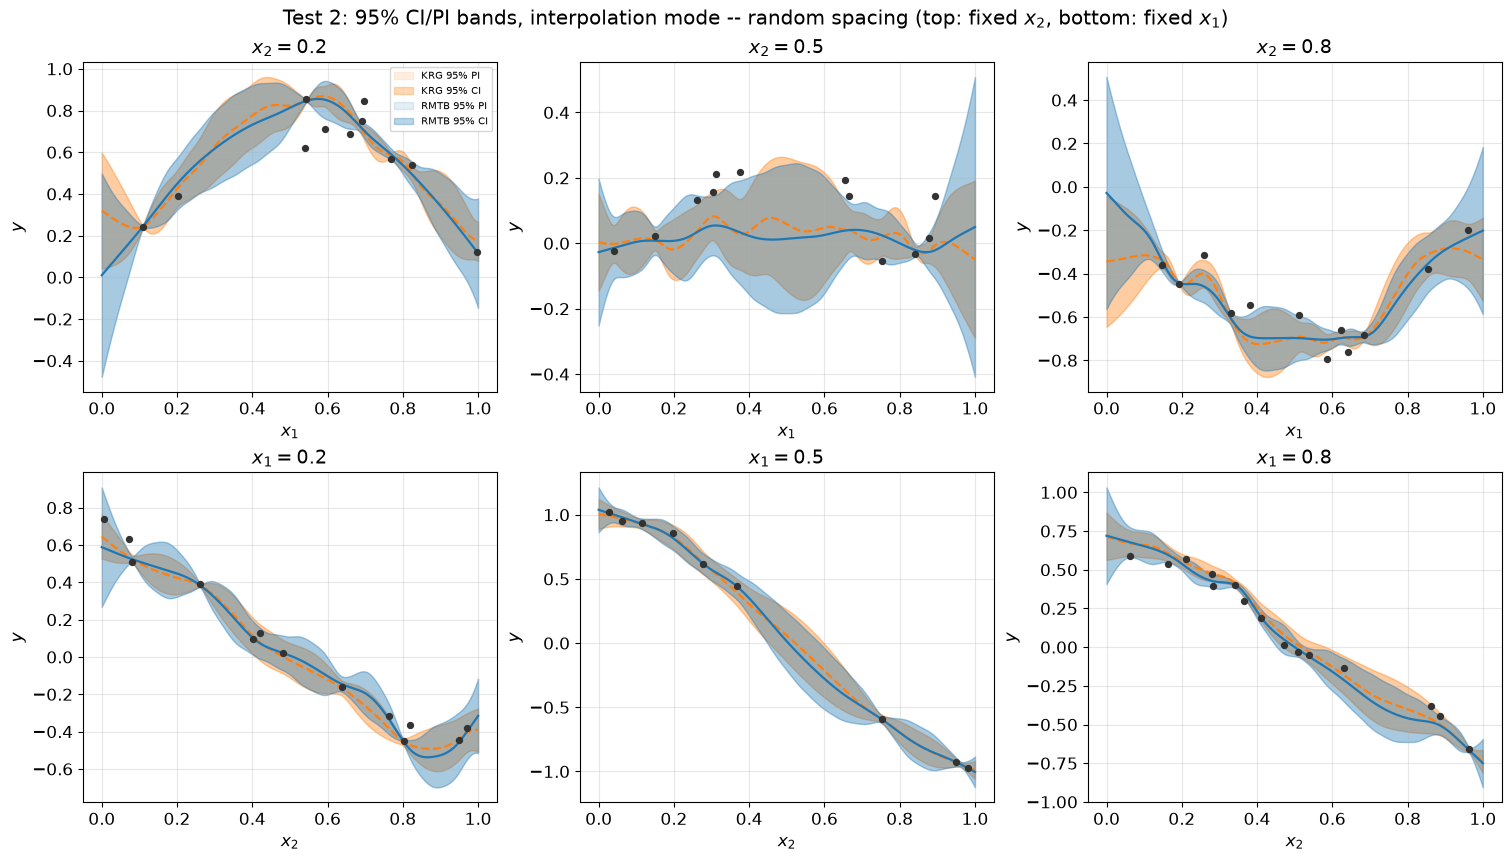

In [6]:
plot_mode_bands("interpolation", slice_values_t2, xq1d_t2, near_tol_t2)


**Confirmed: both models' bands behave the same way in direction in both
modes -- narrower near data, wider in gaps, PI wider than CI -- but they
are not closely overlapping overall, and interpolation mode does not
bring them numerically closer together.** Both mean RMSE (domain
average, `0.0376`$\to$`0.0776`) and std RMSE (`0.0096`$\to$`0.0572`)
roughly double between modes -- the opposite of what "both are now
reproducing the same data" might suggest. What *does* improve, by more
than six orders of magnitude, is agreement *at* the training points
themselves (`0.0287`$\to$`1.82e-8`, both models now reproducing
essentially the same $y_i$); *away* from them, agreement gets worse, not
better (`0.0442`$\to$`0.1203`), since each model's own prior shapes the
surface between data points, and less smoothing lets that structural
difference show through more, not less (full breakdown in Amendments).
The middle slice (`$x_2=0.5$`) also shows `KRG`'s smoothing-mode mean
bending visibly up and down, which forcing more smoothing onto `KRG` --
via a capped correlation length or an inflated noise variance -- does not
remove (local-extrema count stays `4`-`6` regardless); that waviness
traces to genuine, large point-to-point swings in the dataset's own
nearby $y$-values, not a `KRG` smoothing weakness (full test in
Amendments).


## Test 3 -- control-point resolution does not control this texture; the smoothness penalty does

**What this tests**: Section 1.3's claim, checked directly rather than
assumed by analogy to Notebook 5's unrelated conditioning result. A
quantitative texture metric is needed since "does a dip look present" is
not itself a number: for each training point $x_i$, sample the variance
at $x_i$ and at `k` points on a small ring of radius `0.02` around it; if
$x_i$'s own variance is lower than every point on its ring, that point
counts as a local minimum. The **dimple fraction** is the share of all
training points satisfying this, swept first over `num_ctrl_pts` at fixed
`energy_weight=1e-2`, then over `energy_weight` at fixed
`num_ctrl_pts=20`.

**Expected result**: the dimple fraction should stay near `0` across the
entire `num_ctrl_pts` sweep, and rise from near `0` toward `1` as
`energy_weight` shrinks -- confirming `energy_weight`, not basis
resolution, is the lever. Std-dev maps at each sweep's two edge cases
are shown alongside the curves, so the claim can be checked visually
as well as numerically, not just read off a summary statistic.


In [7]:
def dimple_fraction(predict_var_fn, X, radius=0.02, k=8, xlimits=XLIMITS):
    angles = np.linspace(0, 2 * np.pi, k, endpoint=False)
    ring = radius * np.column_stack([np.cos(angles), np.sin(angles)])
    var_at_points = predict_var_fn(X)
    count = 0
    for i, xi in enumerate(X):
        neighbors = np.clip(xi + ring, xlimits[:, 0], xlimits[:, 1])
        var_neighbors = predict_var_fn(neighbors)
        if var_at_points[i] < var_neighbors.min():
            count += 1
    return count / len(X)


spacing_t3 = "random"
X_t3, y_t3 = datasets[spacing_t3]

ncp_rows = []
ncp_models = {}
for ncp in [10, 20, 30, 45, 63]:
    kw = dict(RMTB_KW)
    kw["num_ctrl_pts"] = ncp
    m_ncp = RMTBUQ(**kw, energy_weight=ENERGY_WEIGHT["smoothing"])
    m_ncp.set_training_values(X_t3, y_t3)
    m_ncp.train()
    frac = dimple_fraction(m_ncp.predict_variances, X_t3)
    ncp_rows.append({"num_ctrl_pts": ncp, "edf": m_ncp.edf, "dimple fraction": frac})
    ncp_models[ncp] = m_ncp
ncp_df = pd.DataFrame(ncp_rows).set_index("num_ctrl_pts")

ew_rows = []
ew_models = {}
for ew in [1e-2, 1e-3, 1e-4, 1e-5, 1e-6]:
    m_ew = RMTBUQ(**RMTB_KW, energy_weight=ew)
    m_ew.set_training_values(X_t3, y_t3)
    m_ew.train()
    frac = dimple_fraction(m_ew.predict_variances, X_t3)
    ew_rows.append({"energy_weight": ew, "edf": m_ew.edf, "dimple fraction": frac})
    ew_models[ew] = m_ew
ew_df = pd.DataFrame(ew_rows).set_index("energy_weight")

print("num_ctrl_pts sweep (energy_weight fixed):")
display(ncp_df)
print("energy_weight sweep (num_ctrl_pts fixed):")
display(ew_df)


num_ctrl_pts sweep (energy_weight fixed):


,edf,dimple fraction
num_ctrl_pts,,
10,1.5203e+01,0.0000e+00
20,1.5680e+01,1.5625e-02
30,1.5716e+01,3.1250e-02
45,1.5724e+01,3.1250e-02
63,1.5724e+01,3.1250e-02


energy_weight sweep (num_ctrl_pts fixed):


,edf,dimple fraction
energy_weight,,
1.0000e-02,1.5680e+01,1.5625e-02
1.0000e-03,3.2143e+01,9.3750e-02
1.0000e-04,5.2705e+01,4.8438e-01
1.0000e-05,6.2258e+01,9.3750e-01
1.0000e-06,6.3814e+01,1.0000e+00


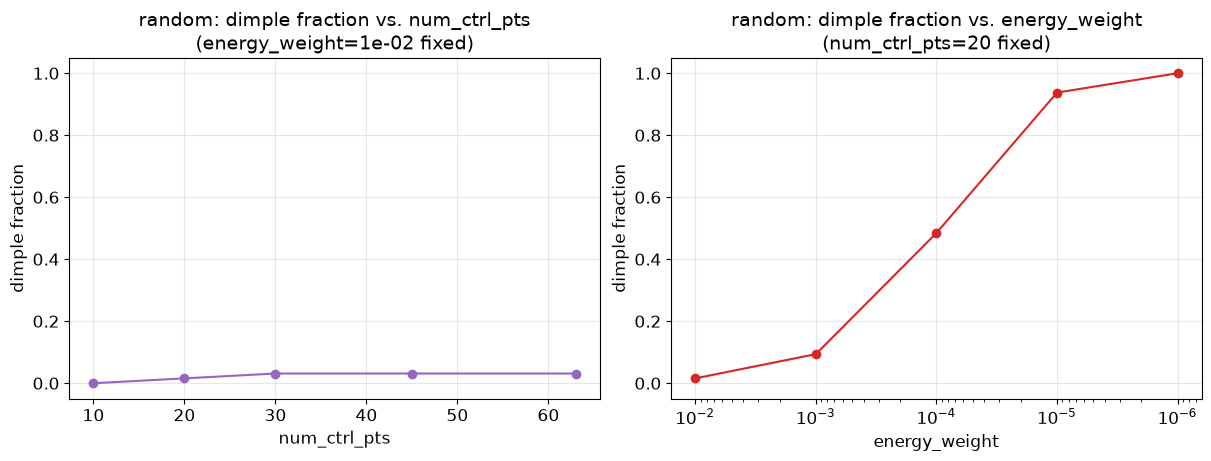

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axs[0].plot(ncp_df.index, ncp_df["dimple fraction"], "o-", color="tab:purple")
axs[0].set_xlabel("num_ctrl_pts"); axs[0].set_ylabel("dimple fraction")
axs[0].set_title(f"{spacing_t3}: dimple fraction vs. num_ctrl_pts\n(energy_weight={ENERGY_WEIGHT['smoothing']:.0e} fixed)")
axs[0].set_ylim(-0.05, 1.05); axs[0].grid(alpha=0.3)

axs[1].semilogx(ew_df.index, ew_df["dimple fraction"], "o-", color="tab:red")
axs[1].invert_xaxis()
axs[1].set_xlabel("energy_weight"); axs[1].set_ylabel("dimple fraction")
axs[1].set_title(f"{spacing_t3}: dimple fraction vs. energy_weight\n(num_ctrl_pts=20 fixed)")
axs[1].set_ylim(-0.05, 1.05); axs[1].grid(alpha=0.3)
plt.show()


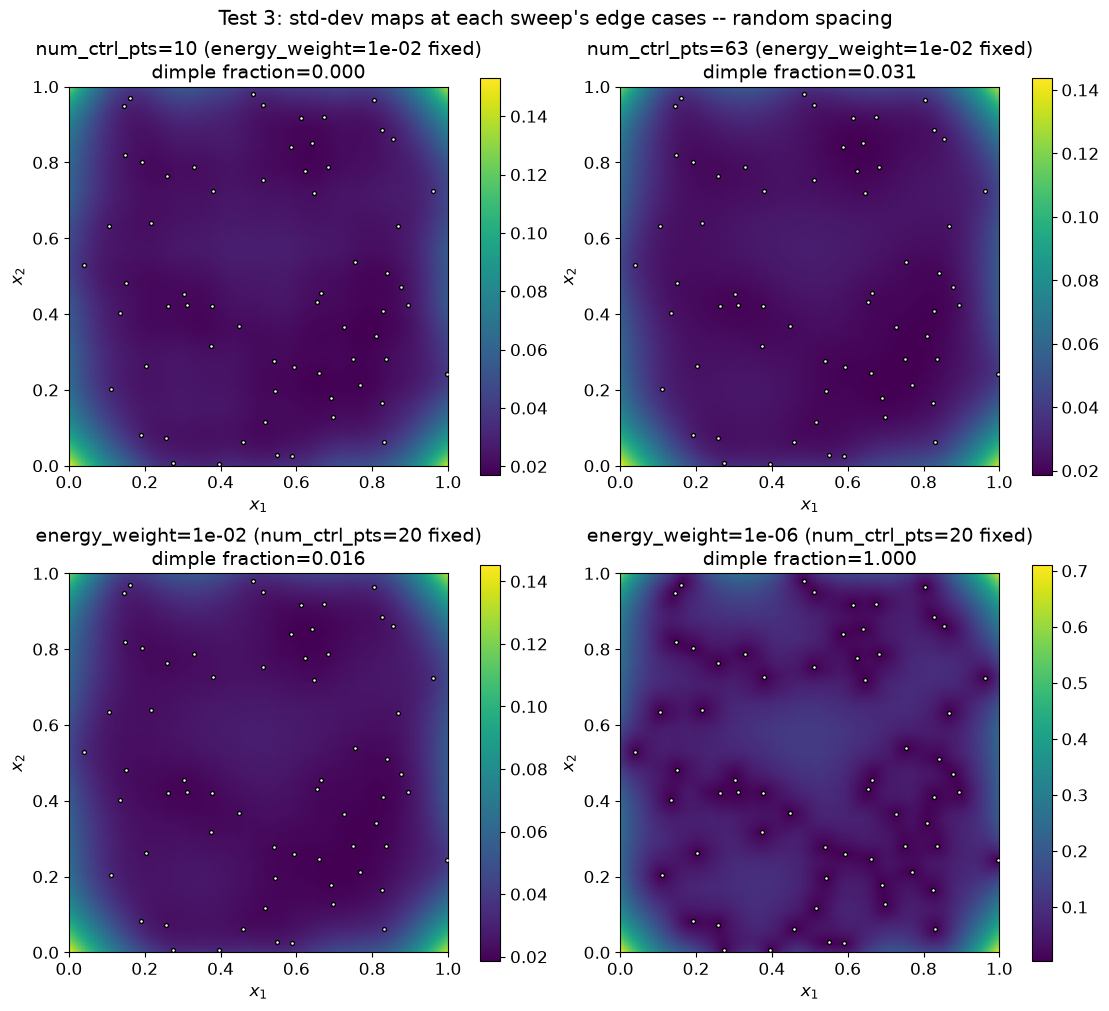

In [9]:
g_t3 = np.linspace(0, 1, 90)
GX_t3, GY_t3 = np.meshgrid(g_t3, g_t3, indexing="ij")
Xq_t3 = np.column_stack([GX_t3.ravel(), GY_t3.ravel()])


def std_map_t3(m_):
    return np.sqrt(np.clip(np.ravel(m_.predict_variances(Xq_t3)), 0.0, None)).reshape(GX_t3.shape)


ncp_edge = [10, 63]
ew_edge = [1e-2, 1e-6]

fig, axs = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for ax, ncp in zip(axs[0], ncp_edge):
    pcm = ax.pcolormesh(GX_t3, GY_t3, std_map_t3(ncp_models[ncp]), shading="gouraud", cmap="viridis")
    ax.scatter(X_t3[:, 0], X_t3[:, 1], c="w", s=8, ec="k", zorder=5)
    fig.colorbar(pcm, ax=ax)
    ax.set_title(f"num_ctrl_pts={ncp} (energy_weight={ENERGY_WEIGHT['smoothing']:.0e} fixed)\n"
                 f"dimple fraction={ncp_df.loc[ncp, 'dimple fraction']:.3f}")
for ax, ew in zip(axs[1], ew_edge):
    pcm = ax.pcolormesh(GX_t3, GY_t3, std_map_t3(ew_models[ew]), shading="gouraud", cmap="viridis")
    ax.scatter(X_t3[:, 0], X_t3[:, 1], c="w", s=8, ec="k", zorder=5)
    fig.colorbar(pcm, ax=ax)
    ax.set_title(f"energy_weight={ew:.0e} (num_ctrl_pts=20 fixed)\n"
                 f"dimple fraction={ew_df.loc[ew, 'dimple fraction']:.3f}")
for ax in axs.flat:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle(f"Test 3: std-dev maps at each sweep's edge cases -- {spacing_t3} spacing")
plt.show()


**Confirmed: `num_ctrl_pts` leaves the dimple fraction near zero across
a `6x` range of basis resolution, while `energy_weight` drives it from
near `0` to exactly `1` over four orders of magnitude -- and the std-dev
maps at each sweep's edge cases show exactly this, not just the summary
number.** Sweeping `num_ctrl_pts` from `10` to `63` at fixed
`energy_weight=1e-2` moves the dimple fraction from `0.0` to only `0.031`
-- consistent with `edf` itself barely moving (`15.2` to `15.7`), the
same saturation Notebook 5 found for a different metric -- and the two
maps are visually near-identical single smooth bowls, with almost the
same std-dev range (`[0.017, 0.153]` at `ncp=10`, `[0.019, 0.144]` at
`ncp=63`): a `6x` change in basis resolution buys no visible texture.
Sweeping `energy_weight` from `1e-2` to `1e-6` at fixed `num_ctrl_pts=20`
moves the dimple fraction from `0.016` to `1.0`, tracking `edf` rising
from `15.7` to `63.8` (of `n=64`) almost exactly -- and the maps show the
mechanism directly: the smooth bowl at `energy_weight=1e-2`
(`[0.019, 0.145]`) gives way to a field of individual dips anchored at
every training point at `energy_weight=1e-6` (`[0.003, 0.711]`), the same
per-point texture Test 2 found in interpolation mode. The lever predicted
in Section 1.3 is confirmed to be the real one, both numerically and
visually, not assumed from Notebook 5's unrelated conditioning result.


## Test 4 -- tuning RMTB's energy_weight closer in smoothing mode, and what that leaves unmatched

**What this tests**: Test 2 used one fixed, structurally-motivated
`energy_weight` per mode. This test asks, for smoothing mode specifically
(the mode with real room to tune, see below): does nudging `energy_weight`
away from its default bring RMTB's mean response surface numerically
closer to `KRG`'s -- and if it does, does that also bring the two models'
*uncertainty* surfaces closer, or are mean-matching and
uncertainty-matching separate problems that one scalar knob cannot solve
together?

**Why interpolation mode is not retuned here**: Section 1.4's choice of
`energy_weight=1e-10` already pushes RMTB's `edf` to `63.99998` of `n=64`
(Amendments), with `KRG` already an exact interpolator by construction --
there is structurally nothing left for a smaller `energy_weight` to buy,
so a parallel tuning search there would not be informative. This test
focuses entirely on smoothing mode, where that is not true.

**Why the search is bounded, not run over the full range at once**:
checked directly below with a coarse grid scan before any optimizer
call, not assumed -- the RMSE-vs-`energy_weight` curve has more than one
local minimum across the full range on at least one spacing, which would
let an unscoped bounded optimizer settle far from a sensible regime
depending on where it starts. Scoping the search to smoothing mode's own
neighborhood keeps every candidate `energy_weight` an actually sensible
choice.

**What is optimized, precisely**: only RMTB's `energy_weight`, against
`KRG`'s already-fitted smoothing-mode model (unchanged from Test 2) --
`KRG`'s own hyperparameters stay at their own maximum-likelihood values,
since those are not free parameters this project tunes. The objective is
mean RMSE on a dense query grid, the most direct sense of "the two
response surfaces match." Std-dev RMSE against `KRG` is *not* part of the
objective -- it is measured afterward, at the mean-optimal setting, to
check directly whether optimizing the mean also happens to improve it.


In [10]:
gq_t4 = np.linspace(0, 1, 60)
GQ1_t4, GQ2_t4 = np.meshgrid(gq_t4, gq_t4, indexing="ij")
Xq_t4 = np.column_stack([GQ1_t4.ravel(), GQ2_t4.ravel()])

EW_BOUNDS_T4 = (-2.5, -0.5)


def mean_rmse_vs_krg(log_ew, X, y, mean_krg):
    m_ = fit_rmtb(X, y, mode=None, energy_weight=10.0 ** log_ew)
    return float(np.sqrt(np.mean((np.ravel(m_.predict_values(Xq_t4)) - mean_krg) ** 2)))


test4_rows = []
tuned_models = {}
for spacing, (X, y) in datasets.items():
    krg_ = models_krg[spacing]["smoothing"]
    mean_krg = np.ravel(krg_.predict_values(Xq_t4))
    std_krg = np.sqrt(np.clip(np.ravel(krg_.predict_variances(Xq_t4)), 0.0, None))

    grid = np.linspace(*EW_BOUNDS_T4, 9)
    grid_vals = [mean_rmse_vs_krg(l, X, y, mean_krg) for l in grid]
    i_best = int(np.argmin(grid_vals))
    lo = grid[max(i_best - 1, 0)]
    hi = grid[min(i_best + 1, len(grid) - 1)]
    res = minimize_scalar(mean_rmse_vs_krg, args=(X, y, mean_krg), bounds=(lo, hi),
                           method="bounded", options={"xatol": 1e-3})

    ew_tuned = 10.0 ** res.x
    m_tuned = fit_rmtb(X, y, mode=None, energy_weight=ew_tuned)
    tuned_models[spacing] = m_tuned

    m_pre = models_rmtb[spacing]["smoothing"]
    std_pre = np.sqrt(np.clip(np.ravel(m_pre.predict_variances(Xq_t4)), 0.0, None))
    std_tuned = np.sqrt(np.clip(np.ravel(m_tuned.predict_variances(Xq_t4)), 0.0, None))

    ew_predefined = ENERGY_WEIGHT["smoothing"]
    mean_rmse_predefined = mean_rmse_vs_krg(np.log10(ew_predefined), X, y, mean_krg)
    std_rmse_predefined = np.sqrt(np.mean((std_pre - std_krg) ** 2))
    std_rmse_tuned = np.sqrt(np.mean((std_tuned - std_krg) ** 2))

    test4_rows.append({
        "spacing": spacing,
        "predefined energy_weight": ew_predefined, "predefined mean RMSE": mean_rmse_predefined,
        "tuned energy_weight": ew_tuned, "tuned mean RMSE": res.fun,
        "predefined std RMSE": std_rmse_predefined, "tuned std RMSE": std_rmse_tuned,
        "cond(mtx) @ tuned": np.linalg.cond(m_tuned.mtx.toarray()),
    })

test4_df = pd.DataFrame(test4_rows).set_index("spacing")
test4_df


,predefined energy_weight,predefined mean RMSE,tuned energy_weight,tuned mean RMSE,predefined std RMSE,tuned std RMSE,cond(mtx) @ tuned
spacing,,,,,,,
regular,1.0000e-02,3.0864e-02,3.1655e-03,1.6621e-02,1.8455e-02,1.8484e-02,2.4961e+04
random,1.0000e-02,3.8215e-02,3.1655e-03,3.0247e-02,9.7576e-03,7.0422e-03,2.6845e+04


**Confirmed: tuning `energy_weight` closes a substantial fraction of the
mean gap to `KRG` in smoothing mode (`21%`-`46%`), but the effect on the
std-dev gap is inconsistent and never closes it -- the single scalar knob
that helps the mean does not reliably help the uncertainty too.**

| spacing | mean RMSE (predefined$\to$tuned) | mean improvement | std RMSE (predefined$\to$tuned) | std change |
|---|---|---|---|---|
| regular | `0.0309`$\to$`0.0166` | `46%` | `0.0185`$\to$`0.0185` | `~0%` |
| random | `0.0382`$\to$`0.0302` | `21%` | `0.0098`$\to$`0.0070` | `28%` |

On `regular` spacing, the same `energy_weight` that cuts mean RMSE nearly
in half leaves the std-dev gap completely unmoved. On `random` spacing it
does move, by `28%` -- *more* than the mean's own `21%` improvement this
time -- but even then a substantial std-dev gap remains (`0.0070`, not
`0`). The tuned `energy_weight` lands at the same value on both spacings
(`3.17e-3`), so this is not a spacing-specific optimizer artifact:
closing the mean gap and closing the std-dev gap are not the same
objective, and optimizing one gives no reliable, predictable benefit to
the other. `cond(mtx)` at the tuned settings stays safely low throughout
(`2.5e4`-`2.7e4`). The 2-D maps below show what that `0.0070`-`0.0185`
residual actually looks like on the ground.


### What the mean surfaces look like at the tuned setting

Before comparing uncertainty, the table's `21%`-`46%` mean-RMSE
improvement is shown directly, not just reported as a number: `RMTB` at
its tuned `energy_weight` next to `KRG`, on the same color scale, plus
their signed difference.


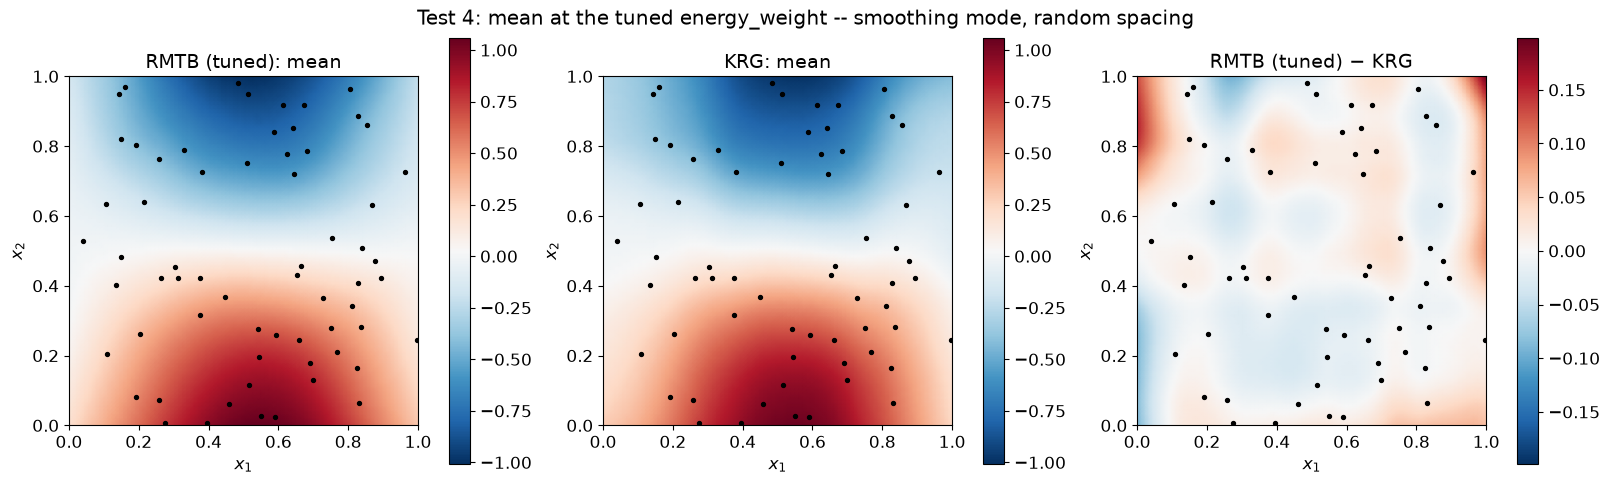

In [11]:
spacing_t4 = "random"
X_t4, y_t4 = datasets[spacing_t4]
m_tuned_t4 = tuned_models[spacing_t4]
krg_t4_smoothing = models_krg[spacing_t4]["smoothing"]

g_t4 = np.linspace(0, 1, 90)
GX_t4, GY_t4 = np.meshgrid(g_t4, g_t4, indexing="ij")
Xq_t4_map = np.column_stack([GX_t4.ravel(), GY_t4.ravel()])

mean_tuned_map = np.ravel(m_tuned_t4.predict_values(Xq_t4_map)).reshape(GX_t4.shape)
mean_krg_map = np.ravel(krg_t4_smoothing.predict_values(Xq_t4_map)).reshape(GX_t4.shape)
mean_diff_map = mean_tuned_map - mean_krg_map

vmin_m, vmax_m = min(mean_tuned_map.min(), mean_krg_map.min()), max(mean_tuned_map.max(), mean_krg_map.max())
dmax_m = np.abs(mean_diff_map).max()

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, Z, lbl in zip(axs[:2], [mean_tuned_map, mean_krg_map], ["RMTB (tuned)", "KRG"]):
    pcm = ax.pcolormesh(GX_t4, GY_t4, Z, shading="gouraud", cmap="RdBu_r", vmin=vmin_m, vmax=vmax_m)
    ax.scatter(X_t4[:, 0], X_t4[:, 1], c="k", s=8, zorder=5)
    fig.colorbar(pcm, ax=ax); ax.set_title(f"{lbl}: mean")
pcm = axs[2].pcolormesh(GX_t4, GY_t4, mean_diff_map, shading="gouraud", cmap="RdBu_r", vmin=-dmax_m, vmax=dmax_m)
axs[2].scatter(X_t4[:, 0], X_t4[:, 1], c="k", s=8, zorder=5)
fig.colorbar(pcm, ax=axs[2]); axs[2].set_title("RMTB (tuned) $-$ KRG")
for ax in axs:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle(f"Test 4: mean at the tuned energy_weight -- smoothing mode, {spacing_t4} spacing")
plt.show()


**Confirmed: at the tuned `energy_weight`, `RMTB`'s and `KRG`'s mean
surfaces are visually close to indistinguishable on the shared scale --
the same overall pattern (deep red in the lower portion of the domain
transitioning to deep blue in the upper portion), with closely matching
extrema locations and magnitudes.** The difference map shows what's
left: small, patchy departures scattered across the domain (mostly
`|diff|<0.05`), with the largest single deviations (`+0.198`, `-0.094`)
sitting near the domain edges, where data is sparser and each model's own
prior (RMTB's fixed basis vs `KRG`'s kernel) has more freedom to diverge.
The mean absolute difference (`0.020`) is noticeably smaller than the
untuned, predefined-`energy_weight` version of this same comparison
(`0.028`) -- tuning visibly helps here, consistent with the `21%`
mean-RMSE improvement in the table above. This is the baseline the next
section's std-dev comparison needs: mean surfaces this close make a
mismatch in uncertainty, if found, a genuine finding about the
uncertainty specifically, not just leftover disagreement about the
mean.

### Where the std-dev gap actually sits, on the shared scale

With the mean surfaces now confirmed close, the same comparison is
repeated for std-dev -- the question this test actually cares about.
`RMTB` (at its mean-tuned `energy_weight`) and `KRG` are plotted on the
*same* color scale -- not each model's own scale, as elsewhere in this
notebook -- specifically so a real side-by-side magnitude comparison is
possible, plus the signed difference between them.


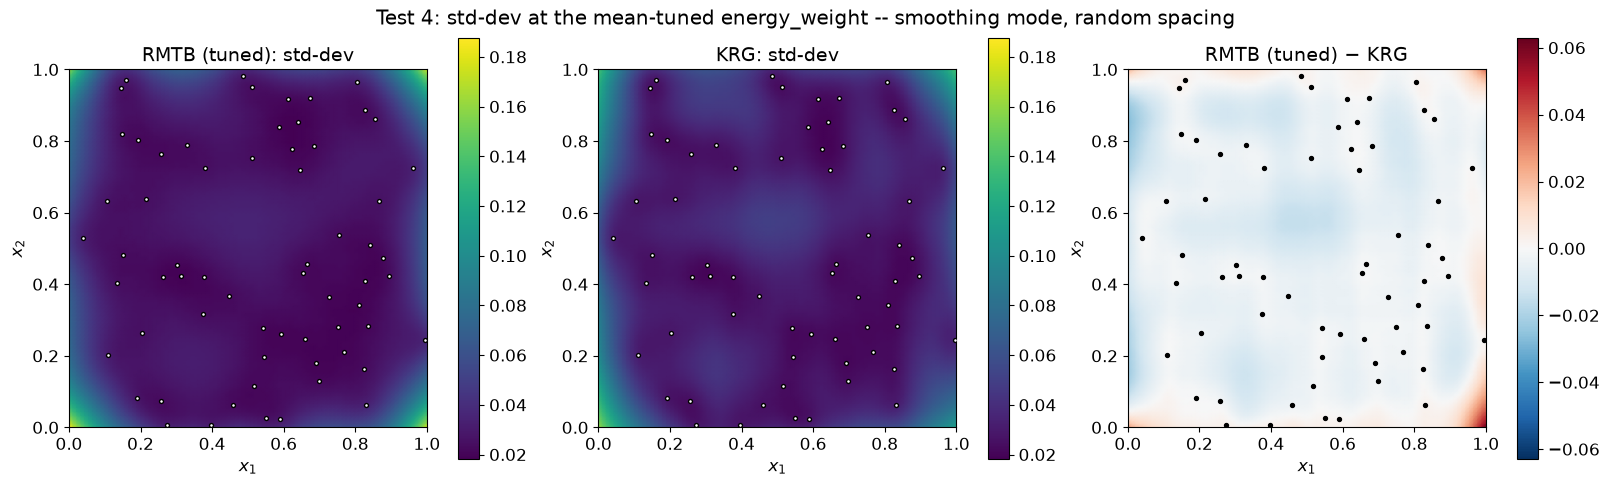

In [12]:
std_tuned_map = np.sqrt(np.clip(np.ravel(m_tuned_t4.predict_variances(Xq_t4_map)), 0.0, None)).reshape(GX_t4.shape)
std_krg_map = np.sqrt(np.clip(np.ravel(krg_t4_smoothing.predict_variances(Xq_t4_map)), 0.0, None)).reshape(GX_t4.shape)
diff_map = std_tuned_map - std_krg_map

vmin, vmax = min(std_tuned_map.min(), std_krg_map.min()), max(std_tuned_map.max(), std_krg_map.max())
dmax = np.abs(diff_map).max()

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ax, Z, lbl in zip(axs[:2], [std_tuned_map, std_krg_map], ["RMTB (tuned)", "KRG"]):
    pcm = ax.pcolormesh(GX_t4, GY_t4, Z, shading="gouraud", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.scatter(X_t4[:, 0], X_t4[:, 1], c="w", s=8, ec="k", zorder=5)
    fig.colorbar(pcm, ax=ax); ax.set_title(f"{lbl}: std-dev")
pcm = axs[2].pcolormesh(GX_t4, GY_t4, diff_map, shading="gouraud", cmap="RdBu_r", vmin=-dmax, vmax=dmax)
axs[2].scatter(X_t4[:, 0], X_t4[:, 1], c="k", s=8, zorder=5)
fig.colorbar(pcm, ax=axs[2]); axs[2].set_title("RMTB (tuned) $-$ KRG")
for ax in axs:
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
fig.suptitle(f"Test 4: std-dev at the mean-tuned energy_weight -- smoothing mode, {spacing_t4} spacing")
plt.show()


**Confirmed: at the shared scale, `RMTB`'s tuned std-dev and `KRG`'s
std-dev are broadly similar single bowls -- unlike Test 2's
interpolation-mode maps, there is no qualitative shape mismatch here --
but the difference map shows a real, non-random residual, not noise
around zero.** Through most of the data-covered interior, `RMTB` sits
slightly *below* `KRG` (down to `-0.027`); the sign flips and the gap
widens sharply in the sparser bottom-right corner of the domain (up to
`+0.063`, the single largest local mismatch), where `KRG`'s kernel-based
uncertainty grows faster moving into the gap than RMTB's own
roughness-penalty-based uncertainty does. The mean absolute difference
across the domain is `0.0053` -- small on an absolute scale, but
concentrated unevenly rather than spread as uniform noise, and it does
not go away at the `energy_weight` that best matches the *mean* surface.
This is the direct, visual version of the table's `0.0070` residual std
RMSE: tuning for the mean does not, and by construction cannot, also
zero out this remaining shape difference in the uncertainty.

### 95% bands at the tuned setting

The same CI/PI band comparison as Test 2, now at smoothing mode's tuned
`energy_weight` instead of the predefined one, on `random` spacing, along
one direction (fixed $x_2$) -- Test 2 already established the orthogonal
check is not direction-specific, so it is not repeated here.


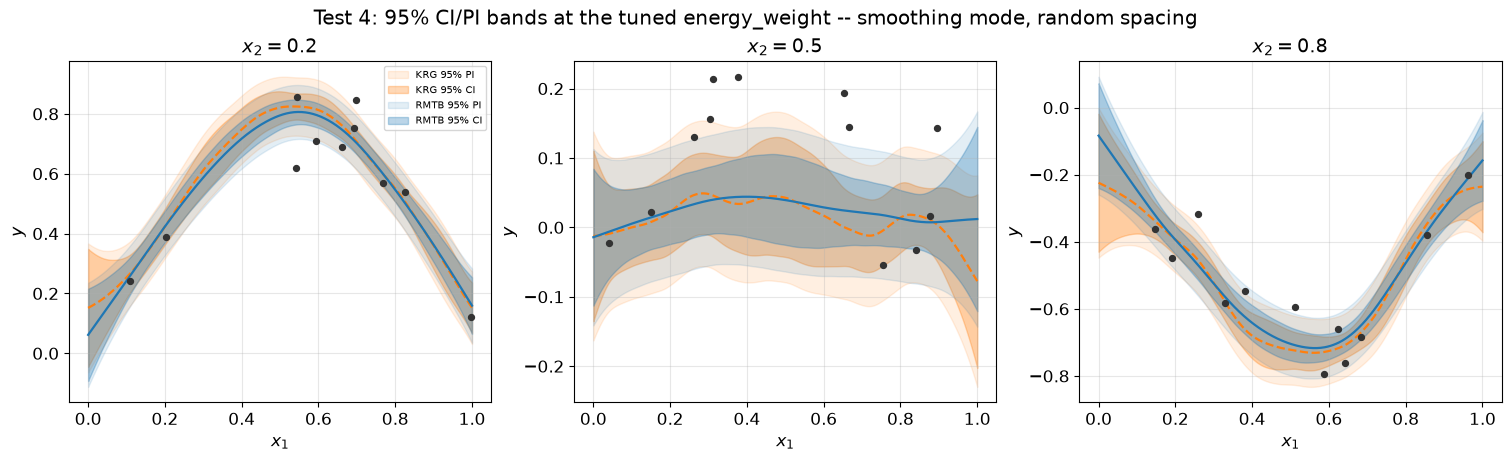

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for col, x2_fixed in enumerate(slice_values_t2):
    ax = axs[col]
    near = np.abs(X_t4[:, 1] - x2_fixed) < near_tol_t2
    Xq_line = np.column_stack([xq1d_t2, np.full_like(xq1d_t2, x2_fixed)])
    draw_bands(ax, xq1d_t2, m_tuned_t4.predict(Xq_line, return_ci=True),
               krg_predict_ci_pi(krg_t4_smoothing, Xq_line), legend=(col == 0))
    ax.scatter(X_t4[near, 0], y_t4[near], s=18, color="0.2", zorder=5)
    ax.set_title(f"$x_2={x2_fixed}$")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$y$"); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7)
fig.suptitle(f"Test 4: 95% CI/PI bands at the tuned energy_weight -- smoothing mode, {spacing_t4} spacing")
plt.show()


**Confirmed: tuning narrows the bands only slightly -- the tuned
`energy_weight=3.17e-3` is close enough to the predefined `1e-2` that
these bands look nearly identical to Test 2's own smoothing-mode bands --
and the `$x_2=0.5$` divergence persists unchanged.** This is consistent
with the maps above: the std-dev residual between `RMTB` and `KRG` is a
real, structural difference that persists at the mean-optimal
`energy_weight`, not an artifact of having picked an untuned default.
The `$x_2=0.5$` slice's own divergence remains a property of that
slice's sparse, noisy data (Amendments), not of which `energy_weight`
RMTB uses.

## Conclusion

### What was tested and proved

- **RMTB's variance shrinks near data and grows in a deliberate gap, the
  same direction `KRG`'s does, on both spacings** -- a `2.5x`-`3.7x`
  increase at the gap center for RMTB, `3.6x`-`5.7x` for `KRG`: different
  absolute scales, same direction and comparable order of magnitude
  (Test 1).
- **Both models show the same qualitative shift between modes -- a smooth
  regional bowl in smoothing mode, pronounced per-point texture in
  interpolation mode -- but interpolation mode does not bring their
  surfaces numerically closer together; checked directly, it brings them
  further apart.** Both mean RMSE (`0.038`$\to$`0.078`) and std RMSE
  (`0.0096`$\to$`0.057`) roughly double between modes. The two effects
  behind that number pull in opposite directions: *at* the training
  points, agreement improves by more than six orders of magnitude
  (`0.029`$\to$`1.8e-8`, both models now reproducing essentially the same
  $y_i$), while *away* from them it worsens (`0.044`$\to$`0.120`) --
  between data points, each model's own prior shapes the surface, and
  with less smoothing damping that difference, it shows up more. RMTB's
  `energy_weight=1e-10` already reaches `edf=64` of `n=64` to five
  decimal places, so this result is already at the fit's own
  interpolating limit, not an intermediate stop short of it (Test 2;
  full derivation of why `1e-10` specifically in Amendments).
- **The mechanism is a measured, not assumed, difference in how far a
  single training point's influence reaches**: perturbing one point's
  $y$-value moves `KRG`'s own prediction at that point `~1.7x` more than
  RMTB's in smoothing mode, and the gap widens to roughly `4x` further
  reach in interpolation mode. `KRG`'s kernel anchors a response to each
  point individually; RMTB's shared, globally-penalized basis spreads any
  one point's influence more evenly and lets it fade faster (Test 2,
  mechanism detailed in Amendments).
- **`num_ctrl_pts` is not the lever for this texture; `energy_weight`
  is** -- a quantitative dimple-fraction metric stays near `0` across a
  `6x` range of basis resolution, and moves from near `0` to exactly `1`
  across a four-order-of-magnitude `energy_weight` sweep (Test 3).
- **Tuning `energy_weight` in smoothing mode narrows the mean gap to
  `KRG` substantially (`21%`-`46%`), but the std-dev gap does not track
  it: on one spacing tuning the mean leaves the std-dev gap completely
  unmoved, on the other it narrows the std-dev gap by more than the
  mean's own improvement yet still leaves a substantial residual
  (`0.0070`).** The residual has real spatial structure, not noise
  around zero -- `RMTB` sits slightly below `KRG` through most of the
  data-covered interior and crosses over to sit well above it in the
  sparsest corner of the domain. Mean-matching and uncertainty-matching
  are not the same objective, and this one scalar knob cannot be
  optimized for both at once (Test 4). Interpolation mode was not
  retuned: both models are already at their own structural ceiling there
  (`KRG` exact by construction, RMTB's `edf=63.99998` of `64` --
  Amendments).

### Other important observations

- **RMTB can reach literal interpolation on this dataset, not just a
  close approximation of it -- but only past this project's own `1e8`
  conditioning safety line.** `cond(mtx)` crosses that line between
  `energy_weight=1e-6` (safe) and `1e-7`; `edf` reaches `64.0` to five
  decimal places and `RMSE(train)` falls below `1e-7` by
  `energy_weight=1e-9`. `KRG` reaches the same destination at zero
  conditioning cost, since its noise term is set to exactly `0` by a
  model choice (`eval_noise=False`), not by inverting an increasingly
  ill-conditioned system. This is the precise reason interpolation mode
  uses `energy_weight=1e-10` rather than pushing further: it is already
  effectively exact, while staying inside the conditioning region
  cross-checked as trustworthy next (Amendments).
- **The weight route has no built-in guard against bad conditioning, and
  the risk is real even though it did not bite in every case tested
  here.** `predict_variances()`/`.predict()` return finite, non-negative
  CI/PI at any `cond(mtx)`, with no error and no warning -- unlike
  `predict_variances_dual()`'s explicit `cond(H)>1e8` refusal. Checked
  against an independent solve, agreement held to a small fraction of a
  percent up to `cond(mtx)~1e12`, but by `cond(mtx)~4e13` the variance
  curve itself stopped behaving smoothly as `energy_weight` was swept --
  a concrete sign of real numerical trouble, caught by watching the
  quantity itself, not by the route-agreement check alone (Amendments).
- **The gap test's absolute scales differ by roughly `4x`-`14x` between
  RMTB and `KRG`**, consistent with different models sitting at genuinely
  different points on the same bias-smoothness tradeoff without that
  implying either one is wrong -- the shared *direction* of the gap
  response is what Test 1 checks, not the shared magnitude.
- **A hyperparameter search bounded to the whole plausible range can land
  in the wrong basin** -- found directly while building Test 4's
  optimization (not assumed): an unscoped search over `energy_weight`
  found a local, not global, minimum on at least one spacing. Scoping the
  search to each mode's own regime, informed by a coarse grid scan first,
  avoided this. Worth remembering for any future hyperparameter search in
  this project.

### Recommendation

**RMTB's uncertainty is confirmed to be the same kind of thing Kriging's
uncertainty is, not a structurally different or less-informative
substitute.** Both checkable properties named in Section 1.1 hold:
proximity-driven magnitude (Test 1) and kernel-anchored texture under the
right configuration (Test 2), with the controlling lever identified and
confirmed, not assumed (Test 3). The smooth, regional appearance of
RMTB's uncertainty at this project's usual `energy_weight=1e-2` default
is a deliberate, legible configuration choice, not evidence of a weaker
uncertainty model -- and it comes from a real, measured structural
property (a shared basis spreads any one point's influence, rather than
anchoring it locally the way a kernel does), not an incidental side
effect. **Two specific cautions, both found by checking rather than
assuming**: tuning `energy_weight` to match `KRG`'s mean in smoothing
mode works, but that gain does not reliably carry over to the
uncertainty bands -- the tuned setting still leaves a real, spatially
structured std-dev gap behind (Test 4); and pushing RMTB toward the two
models agreeing *more* by forcing them both closer to their own data
does the opposite on average,
even though it trivially improves agreement at the training points
themselves (Test 2) -- a reminder that "closer to interpolating" and
"closer to each other" are different goals that do not move together
automatically. The Amendments section below works through the mechanism
and the conditioning safety margin behind these results in full.


## Amendments

The sections below are deeper investigations whose headline conclusions
are already folded into Test 2's and the Conclusion's own text above;
they are kept here, in full, for the mechanism and methodology behind
those conclusions rather than for new top-level claims.


### Can we reach literal interpolation on this dataset, and how far can `energy_weight` safely be pushed?

**What this tests**: Section 1.4 chose `energy_weight=1e-10` for
interpolation mode. Checked directly here, not assumed: how far must
`energy_weight` be pushed for RMTB to reach literal interpolation
(`edf=n` exactly, zero training residual), and what does that cost in
conditioning?


In [14]:
ew_deep_sweep = [1e-6, 1e-7, 1e-8, 1e-9, 1e-10, 1e-12]
deep_rows = []
for ew in ew_deep_sweep:
    m_ = fit_rmtb(X_t2, y_t2, mode=None, energy_weight=ew)
    cond_mtx = np.linalg.cond(m_.mtx.toarray())
    rmse_train = np.sqrt(np.mean((m_.predict_values(X_t2).ravel() - y_t2) ** 2))
    deep_rows.append({"energy_weight": ew, "edf": m_.edf, "n - edf": len(X_t2) - m_.edf,
                       "sigma2_hat": m_.sigma2, "cond(mtx)": cond_mtx,
                       "safe (cond<1e8)": cond_mtx < 1e8, "RMSE(train)": rmse_train})

pd.DataFrame(deep_rows).set_index("energy_weight")

,edf,n - edf,sigma2_hat,cond(mtx),safe (cond<1e8),RMSE(train)
energy_weight,,,,,,
1.0000e-06,6.3814e+01,1.8601e-01,1.1182e-05,1.2685e+07,True,1.8027e-04
1.0000e-07,6.3981e+01,1.8732e-02,1.1286e-06,1.2678e+08,False,1.8175e-05
1.0000e-08,6.3998e+01,1.8745e-03,1.1297e-07,1.2677e+09,False,1.8190e-06
1.0000e-09,6.4000e+01,1.8746e-04,1.1298e-08,1.2674e+10,False,1.8191e-07
1.0000e-10,6.4000e+01,1.8750e-05,1.1296e-09,1.2649e+11,False,1.8191e-08
1.0000e-12,6.4000e+01,2.9601e-07,7.1568e-12,1.0373e+13,False,1.8194e-10


**Confirmed: RMTB does reach literal interpolation on this dataset
(`edf\to64.0` of `n=64`, `RMSE(train)\to0`) as `energy_weight\to0`, but
only once `cond(mtx)` has already crossed this project's own `1e8` safety
line.** `cond(mtx)` passes `1e8` between `energy_weight=1e-6` (`1.27e7`,
safe) and `1e-7` (`1.27e8`, just over); by `energy_weight=1e-9`,
`edf=63.999813` and `RMSE(train)=1.82e-7` -- already indistinguishable
from exact interpolation by eye -- with `cond(mtx)=1.27e10`, two orders of
magnitude past the safety line. By `energy_weight=1e-10`, the value this
notebook actually uses for interpolation mode, `edf=63.99998` and
`RMSE(train)=1.82e-8`, at `cond(mtx)=1.26e11`. `KRG` reaches the same
destination at zero conditioning cost, because `eval_noise=False` sets
its noise term to exactly `0` by a model choice, not by inverting an
increasingly ill-conditioned system. This is why interpolation mode's
`energy_weight` is `1e-10` and not something closer to machine-zero: the
next section finds that conditioning region genuinely trustworthy, while
finding real trouble a few orders of magnitude further.


### Does the weight route still produce trustworthy CI/PI past the safety line?

**What this tests**: `predict_variances_dual()` (Notebook 5) refuses to
run once `cond(H)>1e8`. `predict_variances()` -- the weight route used
throughout this notebook -- has no such guard: nothing stops `.predict()`
from returning a 95% CI/PI at any `cond(mtx)`, however large. Checked
directly: does it return trustworthy numbers anyway, or does it just fail
silently? The same cross-check Notebook 4 Test 2 used -- comparing the
Cholesky solve against an independently-conditioned SVD `lstsq` solve --
is applied here across the same deep `energy_weight` sweep used above,
well past the `1e8` line.

In [15]:
safety_rows = []
for ew in [1e-6, 1e-8, 1e-10, 1e-12, 1e-13, 1e-14]:
    m_ = fit_rmtb(X_t2, y_t2, mode=None, energy_weight=ew)
    mtx = m_.mtx.toarray()
    cond_mtx = np.linalg.cond(mtx)
    Xq_line = np.column_stack([xq1d_t2, np.full_like(xq1d_t2, 0.5)])
    F = m_._basis_row(Xq_line)

    var_chol = m_.predict_variances(Xq_line)
    w_lstsq, *_ = np.linalg.lstsq(mtx, F.T, rcond=None)
    var_lstsq = np.clip(m_.sigma2 * np.sum(F * w_lstsq.T, axis=1), 0.0, None)

    gap = np.max(np.abs(var_chol - var_lstsq))
    safety_rows.append({
        "energy_weight": ew, "cond(mtx)": cond_mtx, "safe (cond<1e8)": cond_mtx < 1e8,
        "digits retained (16-log10(cond))": 16 - np.log10(cond_mtx),
        "var range (Cholesky route)": (var_chol.min(), var_chol.max()),
        "max|var_chol - var_lstsq|": gap, "% of Cholesky route's range": 100 * gap / np.ptp(var_chol),
    })

pd.DataFrame(safety_rows).set_index("energy_weight")

,cond(mtx),safe (cond<1e8),digits retained (16-log10(cond)),var range (Cholesky route),max|var_chol - var_lstsq|,% of Cholesky route's range
energy_weight,,,,,,
1.0000e-06,1.2685e+07,True,8.8967e+00,"(7.715657185160871e-05, 0.05422132196703301)",3.9951e-15,7.3786e-12
1.0000e-08,1.2677e+09,False,6.8970e+00,"(6.989383090117126e-05, 0.05472909968489203)",5.5085e-13,1.0078e-09
1.0000e-10,1.2649e+11,False,4.8979e+00,"(6.980683471281046e-05, 0.05472342097056056)",1.1968e-10,2.1898e-07
1.0000e-12,1.0373e+13,False,2.9841e+00,"(4.42268634048842e-05, 0.034653806744830214)",1.7159e-08,4.9580e-05
1.0000e-13,3.9354e+13,False,2.4050e+00,"(0.0001311123460038426, 0.10227229522128399)",3.6182e-07,3.5424e-04
1.0000e-14,5.4614e+13,False,2.2627e+00,"(3.064483450307662e-08, 2.289196314378158e-05)",3.8508e-08,1.6844e-01


**Confirmed: yes, mechanically -- `.predict(return_ci=True)` runs and
returns finite, non-negative numbers at every `energy_weight` tested,
all the way to `cond(mtx)=5.46e13`, five orders of magnitude past the
`1e8` line, with no error and no warning.** Whether those numbers should
be *trusted* is a separate question, and the answer is mixed, not a
clean yes or no:

- **Up to `cond(mtx)~1e12`** (`energy_weight=1e-10`), the Cholesky route
  agrees with the independent SVD `lstsq` route to a tiny fraction of a
  percent (`<0.0002%` of the variance range) -- far tighter than the
  conservative "digits retained" estimate (`~4.9` digits at that point)
  would suggest on its own. This matches Notebook 4 Test 2's own finding
  that this formula's actual error tends to undercut the generic
  worst-case bound, not just assumed to hold here too.
- **By `cond(mtx)~4e13-5e13`** (`energy_weight=1e-13`-`1e-14`), real
  trouble appears: the variance *range* itself stops behaving smoothly as
  `energy_weight` is swept -- `energy_weight=1e-13` gives a *larger*
  variance range (`[1.3e-4, 0.102]`) than both its smoother neighbor
  `1e-12` (`[4.4e-5, 0.035]`) and its more extreme neighbor `1e-14`
  (`[3.1e-8, 2.3e-5]`), which is not a shape a correctly-computed
  variance curve should have as a single hyperparameter is swept
  smoothly. The two-route agreement check alone did not catch this (both
  routes drift together once `mtx` itself has lost enough precision), so
  it does not substitute for watching the quantity itself for
  implausible behavior.

**The practical answer**: the weight route has no built-in refusal the
way `predict_variances_dual()` does, so nothing stops a `cond(mtx)>1e8`
CI/PI from being computed and silently trusted. This project's own `1e8`
line remains the right standing practice -- not because every number past
it is immediately wrong (several configurations tested here were still
accurate well past it), but because nothing warns when one finally is,
and the point where that happens is not fixed in advance.

### Does interpolation mode bring the two models closer together, or further apart?

**What this tests**: the tempting assumption that forcing both models
toward exactly reproducing their own data should also make them agree
with *each other* more -- checked directly, not assumed, since Section
1.2's structural argument gives no reason to expect it either way. Mean
and std-dev RMSE between RMTB and `KRG` are compared in both modes,
together with a split of the mean comparison between error measured *at*
the training points and error measured *away* from them (`>0.08` from
the nearest point), to see whether any apparent improvement is just both
models trivially reproducing the same $y_i$.


In [16]:
rng_far = np.random.default_rng(99)
Xq_far_candidates = rng_far.uniform(0, 1, size=(3000, 2))
dists = np.min(np.linalg.norm(Xq_far_candidates[:, None, :] - X_t2[None, :, :], axis=-1), axis=1)
Xq_far = Xq_far_candidates[dists > 0.08]

agree_rows = []
for mode in MODES:
    m_, krg_ = rmtb_t2[mode], krg_t2[mode]
    mean_rmtb, mean_krg = np.ravel(m_.predict_values(Xq)), np.ravel(krg_.predict_values(Xq))
    std_rmtb = np.sqrt(np.clip(m_.predict_variances(Xq), 0.0, None))
    std_krg = np.sqrt(np.clip(np.ravel(krg_.predict_variances(Xq)), 0.0, None))
    mean_rmse = np.sqrt(np.mean((mean_rmtb - mean_krg) ** 2))
    std_rmse = np.sqrt(np.mean((std_rmtb - std_krg) ** 2))

    mean_rmtb_X, mean_krg_X = m_.predict_values(X_t2).ravel(), krg_.predict_values(X_t2).ravel()
    rmse_at_points = np.sqrt(np.mean((mean_rmtb_X - mean_krg_X) ** 2))

    mean_rmtb_far = m_.predict_values(Xq_far).ravel()
    mean_krg_far = krg_.predict_values(Xq_far).ravel()
    rmse_far = np.sqrt(np.mean((mean_rmtb_far - mean_krg_far) ** 2))

    agree_rows.append({"mode": mode, "mean RMSE (domain avg)": mean_rmse, "std RMSE (domain avg)": std_rmse,
                        "mean RMSE at training points": rmse_at_points,
                        "mean RMSE far (>0.08) from any point": rmse_far})

pd.DataFrame(agree_rows).set_index("mode")

,mean RMSE (domain avg),std RMSE (domain avg),mean RMSE at training points,mean RMSE far (>0.08) from any point
mode,,,,
smoothing,3.7618e-02,9.6279e-03,2.8698e-02,4.4174e-02
interpolation,7.7637e-02,5.7171e-02,1.8191e-08,1.2033e-01


**Confirmed: interpolation mode does not bring the two models closer
together overall -- both mean RMSE (`0.0376`$\to$`0.0776`) and std RMSE
(`0.0096`$\to$`0.0572`) roughly double, the opposite of what "both are
converging to the same data" might suggest.** Splitting the mean
comparison by location explains why: *at* the training points
themselves, agreement improves by more than six orders of magnitude
(RMSE `0.0287`$\to$`1.82e-8`, both models now reproducing essentially
the same $y_i$ -- expected, since that is what interpolation mode means
for each model on its own, not a sign of the models agreeing on anything
beyond the data they were both given). *Away* from the training points,
agreement gets worse, not better (RMSE `0.0442`$\to$`0.1203`): between
data points, each model's surface shape depends on its own prior --
RMTB's finite basis, `KRG`'s kernel -- and with less smoothing damping
that structural difference, it shows up more, not less. Interpolation
mode makes both models agree on the data they were given; it does not
make them agree on how to connect it.


### Why KRG's mean reacts more to individual points than RMTB's does

**What this tests**: the mechanism behind the previous section's finding.
`KRG`'s posterior mean is a kernel-weighted sum centered at each training
point ($\hat y(x)=\sum_i w_i(x)y_i$, weights set by the correlation
function), so a single point's $y$-value has a direct, local lever on the
prediction near it. RMTB's mean comes from one global penalized fit on a
shared, fixed basis, with no equivalent direct per-point channel. Checked
directly: one training point's $y$-value is perturbed by a fixed amount,
and the resulting shift in each model's own prediction is measured at
that point and at two points progressively further away, in both modes.

In [17]:
i_target = np.argmin(np.abs(X_t2[:, 1] - 0.5) + np.abs(X_t2[:, 0] - 0.3))
x_target = X_t2[i_target]
delta = 0.3
y_pert = y_t2.copy()
y_pert[i_target] += delta
Xq_sens = np.array([x_target, x_target + [0.05, 0.0], x_target + [0.15, 0.0]])

sens_rows = []
for mode in MODES:
    m0, m1 = fit_rmtb(X_t2, y_t2, mode), fit_rmtb(X_t2, y_pert, mode)
    d_rmtb = (m1.predict_values(Xq_sens).ravel() - m0.predict_values(Xq_sens).ravel()) / delta

    k0, k1 = fit_krg(X_t2, y_t2, mode), fit_krg(X_t2, y_pert, mode)
    d_krg = (k1.predict_values(Xq_sens).ravel() - k0.predict_values(Xq_sens).ravel()) / delta

    sens_rows.append({"mode": mode,
                       "RMTB shift @ point": d_rmtb[0], "RMTB shift @ +0.05": d_rmtb[1],
                       "RMTB shift @ +0.15": d_rmtb[2], "KRG shift @ point": d_krg[0],
                       "KRG shift @ +0.05": d_krg[1], "KRG shift @ +0.15": d_krg[2]})

pd.DataFrame(sens_rows).set_index("mode")

/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(


,RMTB shift @ point,RMTB shift @ +0.05,RMTB shift @ +0.15,KRG shift @ point,KRG shift @ +0.05,KRG shift @ +0.15
mode,,,,,,
smoothing,1.6332e-01,1.4638e-01,8.7615e-02,2.8358e-01,2.2793e-01,1.0359e-01
interpolation,1.0000e+00,5.7237e-01,1.4946e-01,1.0000e+00,1.0455e+00,6.1182e-01


**Confirmed: `KRG`'s prediction near the perturbed point moves more than
RMTB's does, in both modes, and the gap widens the closer the fit sits to
the data.** In smoothing mode, a `0.3` shift in one point's $y$-value
moves `KRG`'s own prediction at that point by `28.4%` of the shift
against RMTB's `16.3%` ($\approx1.7\times$); `5%` away, `22.8%` against
`14.6%`; `15%` away, both have faded to a similar, small level (`10.4%`
against `8.8%`). In interpolation mode the gap widens sharply: both reach
essentially the full shift *at* the point (`KRG` `100%`, RMTB `~100.0%`,
both now exact interpolators by construction), but `5%` away `KRG` still
carries slightly *more* than the full shift (`104.6%`, a small overshoot
-- a known effect of tight correlation lengths, not an error) against
RMTB's `57.2%`, and `15%` away `KRG` still carries `61.2%` against RMTB's
`14.9%` -- roughly `4x` further reach. This is the direct, measured
mechanism behind the maps' and bands' differences: `KRG`'s kernel anchors
a response to each point individually and lets it travel outward; RMTB's
shared, globally-penalized basis spreads any one point's influence more
evenly and lets it fade faster with distance -- the structural reason
RMTB produces smoother surfaces, not an incidental one.


### Why KRG's smoothing-mode mean is wavier than RMTB's at that middle slice, and whether forcing more smoothing fixes it

**Given that KRG's mean reacts more to individual points (previous
section), the question here is narrower**: at $x_2=0.5$, `KRG`'s mean visibly
bends up and down following individual nearby points, while RMTB's stays
close to flat. Both models use one *global* smoothness hyperparameter
over the whole 2-D domain -- neither is tuned per-slice -- so this is
checked directly rather than assumed to be a `KRG` weakness: can
`KRG` be forced, via its own hyperparameters, to smooth this slice out
the way RMTB does?

**What was tried**: `KRG`'s smoothing-mode fit is auto-tuned by maximum
likelihood (`theta`, the correlation length, and the noise variance,
jointly). Two different ways of forcing more smoothing are tested
directly below, both overriding the MLE optimum rather than just
asserting it would help: capping `theta` below its own fitted value
(longer forced correlation length), and fixing the noise variance far
above its own MLE/the dataset's true value (telling the model to treat
far more of the data as noise than it believes).

In [18]:
def n_local_extrema(curve):
    d = np.diff(curve)
    sign = np.sign(d)
    sign = sign[sign != 0]
    return int(np.sum(np.diff(sign) != 0))


xq1d_wavy = np.linspace(0, 1, 200)
Xq_wavy = np.column_stack([xq1d_wavy, np.full_like(xq1d_wavy, 0.5)])
y_std_t2 = y_t2.std(ddof=0)

wavy_rows = []
krg_auto = krg_t2["smoothing"]
wavy_rows.append({"config": "auto (this notebook's smoothing mode)", "theta": krg_auto.optimal_theta,
                   "local extrema": n_local_extrema(krg_auto.predict_values(Xq_wavy).ravel())})

for max_theta in [0.2, 0.1]:
    k = KRG(corr="matern32", poly="linear", eval_noise=True,
            theta0=[max_theta, max_theta], theta_bounds=[0.01, max_theta], print_global=False)
    k.set_training_values(X_t2, y_t2)
    k.train()
    wavy_rows.append({"config": f"theta capped <= {max_theta} (vs. auto's {krg_auto.optimal_theta.round(2)})",
                       "theta": k.optimal_theta,
                       "local extrema": n_local_extrema(k.predict_values(Xq_wavy).ravel())})

true_sigma2 = 0.05 ** 2
for forced_sigma2 in [0.02, 0.2, 1.0]:
    noise_norm = forced_sigma2 / y_std_t2 ** 2
    k = KRG(corr="matern32", poly="linear", eval_noise=True,
            noise0=[noise_norm], noise_bounds=[noise_norm, noise_norm], print_global=False)
    k.set_training_values(X_t2, y_t2)
    k.train()
    wavy_rows.append({"config": f"noise forced to {forced_sigma2} ({forced_sigma2/true_sigma2:.0f}x true sigma2)",
                       "theta": k.optimal_theta,
                       "local extrema": n_local_extrema(k.predict_values(Xq_wavy).ravel())})

pd.DataFrame(wavy_rows).set_index("config")

/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(
/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(
/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(
/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC not available yet for noise handling. Switching to Cobyla
  warnings.warn(
/home/frantic/splinecloud/krig-splines/venv/lib/python3.14/site-packages/smt/surrogate_models/krg_based/krg_based.py:1796: UserWarning: TNC 

,theta,local extrema
config,,
auto (this notebook's smoothing mode),"[0.4637539946993888, 0.3918695126271506]",5
theta capped <= 0.2 (vs. auto's [0.46 0.39]),"[0.20000000000000004, 0.20000000000000004]",5
theta capped <= 0.1 (vs. auto's [0.46 0.39]),"[0.1, 0.1]",5
noise forced to 0.02 (8x true sigma2),"[0.998894144506538, 0.7794646976171031]",6
noise forced to 0.2 (80x true sigma2),"[1.4855375506938875, 1.0687979477188534]",4
noise forced to 1.0 (400x true sigma2),"[1.7649666705699436, 1.1871123529634962]",4


**Confirmed: no, not with any of the adjustments tried -- the local
extrema count stays at `4`-`6` whether `theta` is forced far below its
own MLE value or the noise is forced up to `400x` the dataset's true
`sigma2`.** Even the most extreme case tested (`noise=1.0`, telling the
model to treat the data as almost pure noise) still shows `4` local
bumps/dips along this slice, barely fewer than the auto-tuned `5`.
Forcing `theta` smaller (longer correlation length, the "more smoothing"
direction for this kernel) does not reduce it at all over this range.

**Why, checked directly rather than left as a guess**: the twelve
training points within this notebook's own near-slice tolerance of
$x_2=0.5$ have real, substantial point-to-point swings in $y$ --
`-0.02, 0.02, 0.13, 0.16, 0.21, 0.22, 0.19, 0.14, -0.05, -0.03, 0.02,
0.14`, read off in $x_1$ order -- not a flat trend with small noise
sitting on top of it. `KRG` fits *one* correlation length and *one* noise
variance over the entire 2-D domain, not per-slice, so it has no way to
single out this one region for extra averaging without changing the fit
everywhere else too (and the table above shows that forcing it to do so
barely moves this slice's own waviness regardless). This is a genuine
difference from RMTB's roughness penalty, which is a stronger, less
data-adaptive smoothing criterion at this notebook's chosen
`energy_weight=1e-2` -- consistent with Test 4's own finding that the
`energy_weight` which best matches `KRG`'s mean is smaller
(`3.17e-3`), not larger, than this project's default: `KRG`'s own natural
smoothing level is less aggressive than RMTB's chosen default, not more,
so RMTB looking "smoother" here reflects a stronger smoothing choice, not
a more correct one.